# Sales Data Analysis and Business Insights

**Goal:** analyze the 2019 monthly sales files, validate and clean the data, calculate business KPIs, and explore revenue, products, cities, purchase timing, and product combinations.

> **Before you start:** place the 12 original monthly CSV files in a folder named `dataset/` next to this notebook. Expected filenames look like `Sales_January_2019.csv`. Do not put a previously generated `all_data.csv` in that folder.

## 1. Import libraries and configure paths

In [1]:
from pathlib import Path
from itertools import combinations
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path("dataset")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

REQUIRED_COLUMNS = [
    "Order ID", "Product", "Quantity Ordered", "Price Each",
    "Order Date", "Purchase Address"
]
pd.set_option("display.max_columns", 50)

## 2. Load and combine the monthly files
Only monthly source files matching the expected naming pattern are read. This avoids accidentally re-reading a generated merged file.

In [2]:
if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_DIR.resolve()}. Create a 'dataset' folder and add the 12 monthly CSV files."
    )

csv_files = sorted(
    p for p in DATA_DIR.glob("Sales_*_2019.csv")
    if p.is_file() and p.name.lower() != "all_data.csv"
)
if not csv_files:
    raise FileNotFoundError(
        "No files matching 'Sales_*_2019.csv' were found inside the dataset folder."
    )

frames = []
for path in csv_files:
    frame = pd.read_csv(path, dtype=str)
    frame["Source File"] = path.name
    frames.append(frame)

raw_data = pd.concat(frames, ignore_index=True)
missing_columns = sorted(set(REQUIRED_COLUMNS) - set(raw_data.columns))
if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print(f"Files loaded: {len(csv_files)}")
print(f"Combined raw shape: {raw_data.shape}")
display(raw_data.head())

Files loaded: 12
Combined raw shape: (186850, 7)


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Source File
0,176558,USB-C Charging Cable,2,11.95,04/19/19 08:46,"917 1st St, Dallas, TX 75001",Sales_April_2019.csv
1,NaN,NaN,NaN,NaN,NaN,NaN,Sales_April_2019.csv
2,176559,Bose SoundSport Headphones,1,99.99,04/07/19 22:30,"682 Chestnut St, Boston, MA 02215",Sales_April_2019.csv
3,176560,Google Phone,1,600,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv
4,176560,Wired Headphones,1,11.99,04/12/19 14:38,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv


## 3. Audit and clean the data
The cleaning step removes completely empty rows and repeated header rows, converts numeric/date fields safely, and reports rows that cannot be analyzed. Invalid records are excluded from the analysis dataset rather than silently treated as valid.

In [4]:
data = raw_data.copy()
data = data.dropna(how="all")

# Some source files may contain their header as a data row.
header_mask = data["Order Date"].astype(str).str.strip().eq("Order Date")
print("Repeated header rows:", int(header_mask.sum()))
data = data.loc[~header_mask].copy()

for col in ["Order ID", "Product", "Purchase Address"]:
    data[col] = data[col].astype("string").str.strip()

data["Quantity Ordered"] = pd.to_numeric(data["Quantity Ordered"], errors="coerce")
data["Price Each"] = pd.to_numeric(data["Price Each"], errors="coerce")
data["Order Date"] = pd.to_datetime(data["Order Date"], errors="coerce")

invalid_mask = (
    data["Order ID"].isna() | data["Order ID"].eq("") |
    data["Product"].isna() | data["Product"].eq("") |
    data["Purchase Address"].isna() | data["Purchase Address"].eq("") |
    data["Quantity Ordered"].isna() | data["Price Each"].isna() |
    data["Order Date"].isna()
)
print("Rows with missing/invalid required values:", int(invalid_mask.sum()))
data = data.loc[~invalid_mask].copy()

# Exclude impossible sales quantities/prices; review these counts before changing this rule.
nonpositive_mask = (data["Quantity Ordered"] <= 0) | (data["Price Each"] < 0)
print("Rows with non-positive quantity or negative price:", int(nonpositive_mask.sum()))
data = data.loc[~nonpositive_mask].copy()

# Duplicate rows are reported, not automatically removed: identical line items can require business review.
duplicate_count = int(data.duplicated(subset=REQUIRED_COLUMNS).sum())
print("Exact duplicate business rows (reported, not automatically removed):", duplicate_count)

data["Quantity Ordered"] = data["Quantity Ordered"].astype(int)
data["Sales"] = data["Quantity Ordered"] * data["Price Each"]
print("Cleaned analysis shape:", data.shape)
display(data.head())

Repeated header rows: 355


C:\Users\aly\AppData\Local\Temp\ipykernel_34664\2316076357.py:14: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  data["Order Date"] = pd.to_datetime(data["Order Date"], errors="coerce")


Rows with missing/invalid required values: 545
Rows with non-positive quantity or negative price: 0
Exact duplicate business rows (reported, not automatically removed): 264
Cleaned analysis shape: (185950, 8)


,Order ID,Product,Quantity Ordered,Price Each,Order Date,Purchase Address,Source File,Sales
0,176558,USB-C Charging Cable,2,11.95,2019-04-19 08:46:00,"917 1st St, Dallas, TX 75001",Sales_April_2019.csv,23.90
2,176559,Bose SoundSport Headphones,1,99.99,2019-04-07 22:30:00,"682 Chestnut St, Boston, MA 02215",Sales_April_2019.csv,99.99
3,176560,Google Phone,1,600.00,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv,600.00
4,176560,Wired Headphones,1,11.99,2019-04-12 14:38:00,"669 Spruce St, Los Angeles, CA 90001",Sales_April_2019.csv,11.99
5,176561,Wired Headphones,1,11.99,2019-04-30 09:27:00,"333 8th St, Los Angeles, CA 90001",Sales_April_2019.csv,11.99


## 4. Feature engineering
Create month, city/state, hour, weekday, and date fields for the analysis. Address parsing is defensive so malformed addresses do not crash the notebook.

In [6]:
address_parts = data["Purchase Address"].str.split(",", n=2, expand=True)
data["City Name"] = address_parts[1].str.strip() if 1 in address_parts.columns else pd.NA
data["State"] = (
    address_parts[2].str.strip().str.extract(r"([A-Z]{2})\s+\d{5}", expand=False)
    if 2 in address_parts.columns else pd.NA
)
data["City"] = np.where(
    data["City Name"].notna() & data["State"].notna(),
    data["City Name"] + " (" + data["State"] + ")",
    data["City Name"].fillna("Unknown")
)
data["Month"] = data["Order Date"].dt.month
data["Month Name"] = data["Order Date"].dt.month_name()
data["Date"] = data["Order Date"].dt.date
data["Hour"] = data["Order Date"].dt.hour
data["Weekday"] = data["Order Date"].dt.day_name()

display(data[["Order ID", "Product", "Sales", "City", "Month Name", "Hour", "Weekday"]].head())

,Order ID,Product,Sales,City,Month Name,Hour,Weekday
0,176558,USB-C Charging Cable,23.90,Dallas (TX),April,8,Friday
2,176559,Bose SoundSport Headphones,99.99,Boston (MA),April,22,Sunday
3,176560,Google Phone,600.00,Los Angeles (CA),April,14,Friday
4,176560,Wired Headphones,11.99,Los Angeles (CA),April,14,Friday
5,176561,Wired Headphones,11.99,Los Angeles (CA),April,9,Tuesday


## 5. Core business KPIs

In [7]:
total_revenue = data["Sales"].sum()
total_units = data["Quantity Ordered"].sum()
total_orders = data["Order ID"].nunique()
average_order_value = total_revenue / total_orders if total_orders else np.nan

kpis = pd.DataFrame({
    "Metric": ["Total revenue", "Unique orders", "Units sold", "Average order value"],
    "Value": [total_revenue, total_orders, total_units, average_order_value]
})
display(kpis)
kpis.to_csv(OUTPUT_DIR / "sales_kpis.csv", index=False)

,Metric,Value
0,Total revenue,3.449204e+07
1,Unique orders,1.784370e+05
2,Units sold,2.090790e+05
3,Average order value,1.933009e+02


## 6. Monthly revenue trend
This dataset covers 2019 only, so it can compare months within that year but cannot establish a recurring year-over-year seasonal pattern.

,Month,Revenue,Units,Order_Count,Month Name
0,1,1822256.73,10903,9293,Jan
1,2,2202022.42,13449,11496,Feb
2,3,2807100.38,17005,14549,Mar
3,4,3390670.24,20558,17528,Apr
4,5,3152606.75,18667,15836,May
5,6,2577802.26,15253,12989,Jun
6,7,2647775.76,16072,13761,Jul
7,8,2244467.88,13448,11484,Aug
8,9,2097560.13,13109,11202,Sep
9,10,3736726.88,22703,19436,Oct


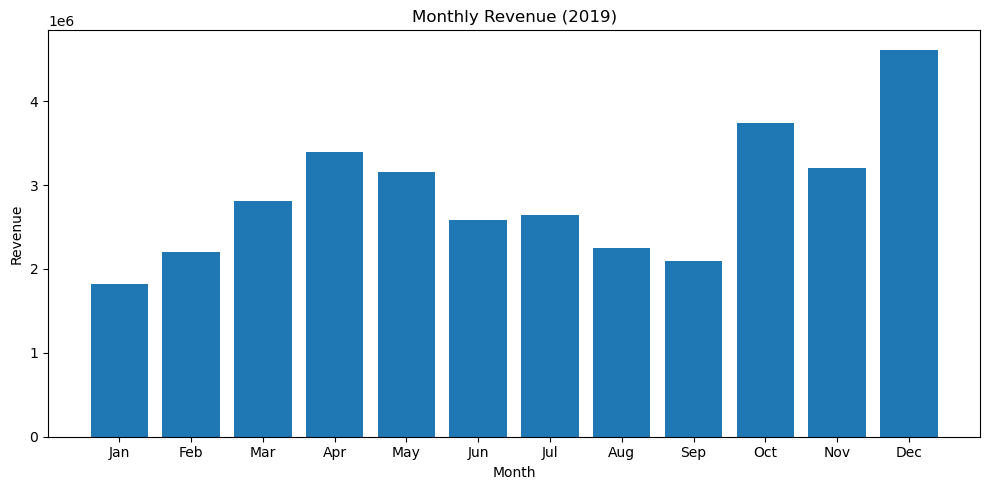

Highest-revenue month in this dataset: Dec ($4,613,443.34)


In [8]:
monthly = (
    data.groupby(["Month"], as_index=False)
    .agg(Revenue=("Sales", "sum"), Units=("Quantity Ordered", "sum"),
         Order_Count=("Order ID", "nunique"))
    .sort_values("Month")
)
monthly["Month Name"] = monthly["Month"].apply(lambda m: pd.Timestamp(2019, int(m), 1).strftime("%b"))
display(monthly)

plt.figure(figsize=(10, 5))
plt.bar(monthly["Month Name"], monthly["Revenue"])
plt.title("Monthly Revenue (2019)")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

best_month = monthly.loc[monthly["Revenue"].idxmax()]
print(f"Highest-revenue month in this dataset: {best_month['Month Name']} (${best_month['Revenue']:,.2f})")
monthly.to_csv(OUTPUT_DIR / "monthly_sales_summary.csv", index=False)

## 7. Revenue by city

,City,Revenue,Units,Order_Count
8,San Francisco (CA),8262203.91,50239,42898
4,Los Angeles (CA),5452570.80,33289,28498
5,New York City (NY),4664317.43,27932,23848
2,Boston (MA),3661642.01,22528,19092
0,Atlanta (GA),2795498.58,16602,14253
3,Dallas (TX),2767975.40,16730,14240
9,Seattle (WA),2747755.48,16553,14119
7,Portland (OR),1870732.34,11303,9617
1,Austin (TX),1819581.75,11153,9509
6,Portland (ME),449758.27,2750,2363


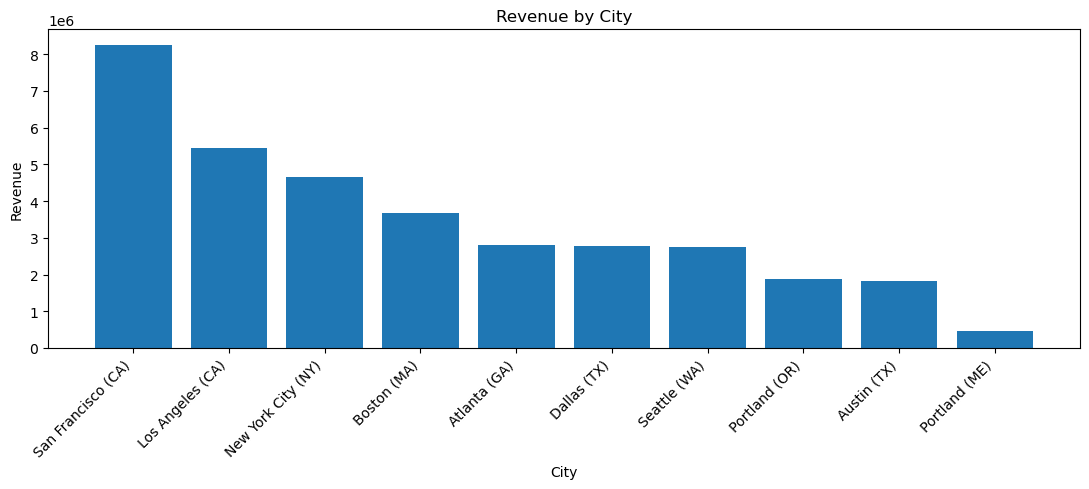

In [9]:
city_summary = (
    data.groupby("City", dropna=False, as_index=False)
    .agg(Revenue=("Sales", "sum"), Units=("Quantity Ordered", "sum"),
         Order_Count=("Order ID", "nunique"))
    .sort_values("Revenue", ascending=False)
)
display(city_summary)

plt.figure(figsize=(11, 5))
plt.bar(city_summary["City"], city_summary["Revenue"])
plt.title("Revenue by City")
plt.xlabel("City")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

city_summary.to_csv(OUTPUT_DIR / "city_sales_summary.csv", index=False)

## 8. Purchase timing: hour and weekday
The charts show the distribution of recorded order-line rows by time. They are useful as a first marketing hypothesis, not proof that advertising at a particular time causes more purchases.

,Hour,Order_Lines,Unique_Orders,Revenue
0,0,3910,3758,713721.27
1,1,2350,2255,460866.88
2,2,1243,1196,234851.44
3,3,831,804,145757.89
4,4,854,814,162661.01
5,5,1321,1259,230679.82
6,6,2482,2375,448113.00
7,7,4011,3836,744854.12
8,8,6256,6036,1192348.97
9,9,8748,8404,1639030.58


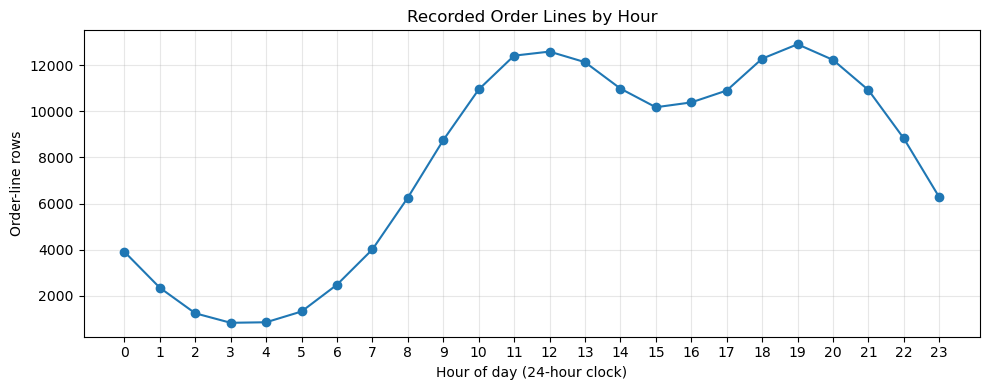

,Weekday,Revenue,Order_Lines,Unique_Orders
1,Monday,4883326.72,26547,25494
5,Tuesday,5087956.78,27175,26063
6,Wednesday,4988822.26,26477,25394
4,Thursday,4839465.16,26461,25368
0,Friday,4855938.38,26247,25216
2,Saturday,4904357.01,26492,25420
3,Sunday,4932169.66,26551,25482


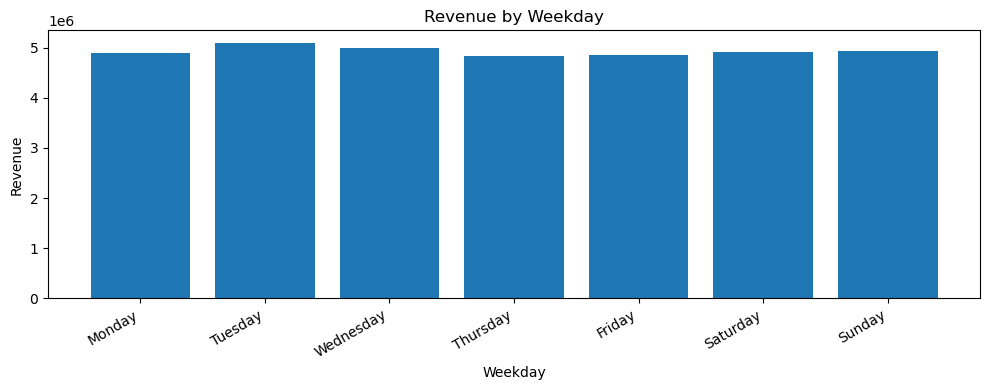

In [10]:
hourly = (
    data.groupby("Hour", as_index=False)
    .agg(Order_Lines=("Order ID", "size"),
         Unique_Orders=("Order ID", "nunique"),
         Revenue=("Sales", "sum"))
    .sort_values("Hour")
)
display(hourly)

plt.figure(figsize=(10, 4))
plt.plot(hourly["Hour"], hourly["Order_Lines"], marker="o")
plt.xticks(range(24))
plt.title("Recorded Order Lines by Hour")
plt.xlabel("Hour of day (24-hour clock)")
plt.ylabel("Order-line rows")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = data.groupby("Weekday", as_index=False).agg(
    Revenue=("Sales", "sum"), Order_Lines=("Order ID", "size"),
    Unique_Orders=("Order ID", "nunique")
)
weekday["Weekday"] = pd.Categorical(weekday["Weekday"], categories=weekday_order, ordered=True)
weekday = weekday.sort_values("Weekday")
display(weekday)

plt.figure(figsize=(10, 4))
plt.bar(weekday["Weekday"].astype(str), weekday["Revenue"])
plt.title("Revenue by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Revenue")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

hourly.to_csv(OUTPUT_DIR / "hourly_sales_summary.csv", index=False)
weekday.to_csv(OUTPUT_DIR / "weekday_sales_summary.csv", index=False)

## 9. Product performance: units and revenue

,Product,Units_Sold,Revenue,Average_Unit_Price,Order_Count
5,AAA Batteries (4-pack),31017,92740.83,2.99,20593
4,AA Batteries (4-pack),27635,106118.40,3.84,20542
15,USB-C Charging Cable,23975,286501.25,11.95,21855
12,Lightning Charging Cable,23217,347094.15,14.95,21604
17,Wired Headphones,20557,246478.43,11.99,18847
6,Apple Airpods Headphones,15661,2349150.00,150.00,15525
7,Bose SoundSport Headphones,13457,1345565.43,99.99,13298
2,27in FHD Monitor,7550,1132424.50,149.99,7498
18,iPhone,6849,4794300.00,700.00,6840
1,27in 4K Gaming Monitor,6244,2435097.56,389.99,6225


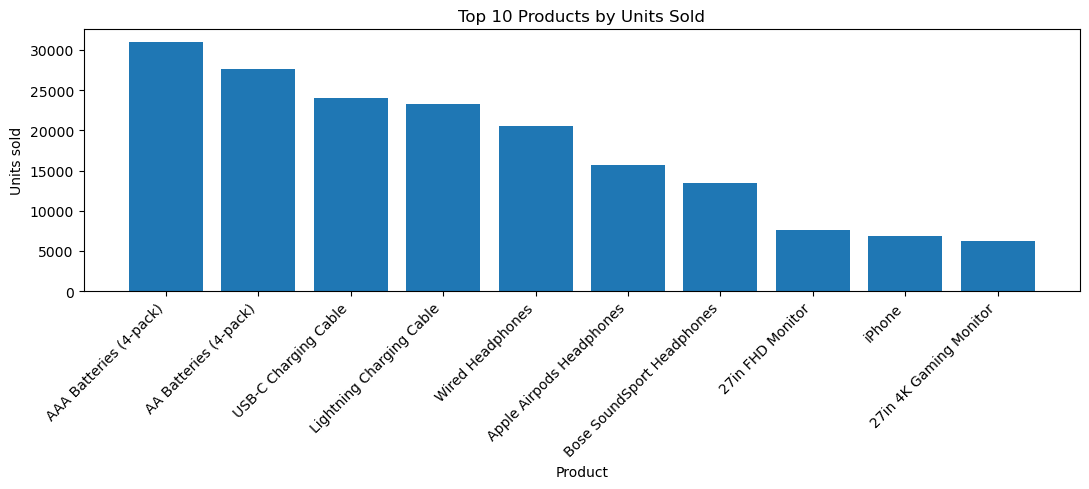

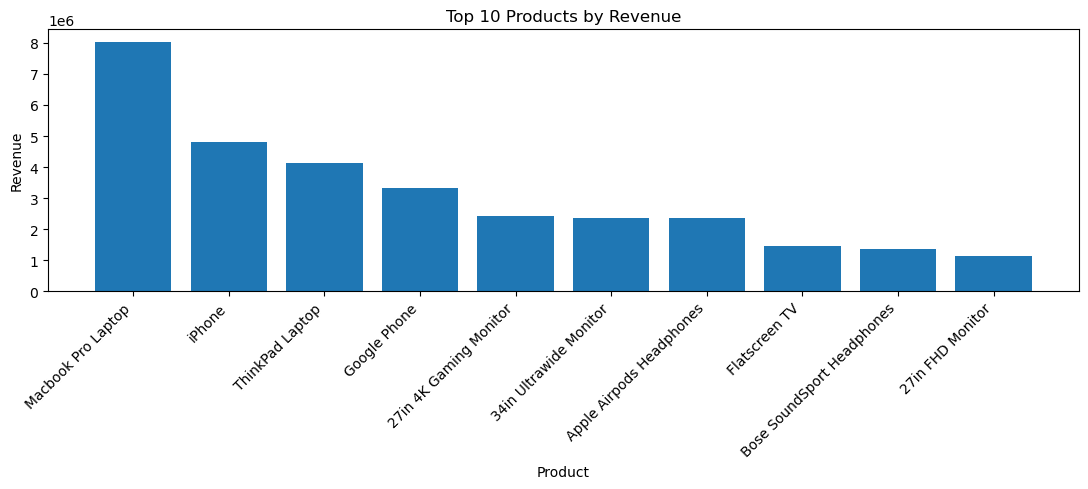

In [11]:
product_summary = (
    data.groupby("Product", as_index=False)
    .agg(Units_Sold=("Quantity Ordered", "sum"),
         Revenue=("Sales", "sum"),
         Average_Unit_Price=("Price Each", "mean"),
         Order_Count=("Order ID", "nunique"))
    .sort_values("Units_Sold", ascending=False)
)
display(product_summary.head(15))

top_units = product_summary.sort_values("Units_Sold", ascending=False).head(10)
plt.figure(figsize=(11, 5))
plt.bar(top_units["Product"], top_units["Units_Sold"])
plt.title("Top 10 Products by Units Sold")
plt.xlabel("Product")
plt.ylabel("Units sold")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

top_revenue = product_summary.sort_values("Revenue", ascending=False).head(10)
plt.figure(figsize=(11, 5))
plt.bar(top_revenue["Product"], top_revenue["Revenue"])
plt.title("Top 10 Products by Revenue")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

product_summary.to_csv(OUTPUT_DIR / "product_performance.csv", index=False)

## 10. Market basket analysis: products bought together
Each order is represented by its **unique products**, preventing repeated rows of the same product within one order from artificially inflating a pair count. Support, confidence, and lift are calculated from order-level baskets. These are associations, not evidence of causation.

In [12]:
baskets = (
    data.groupby("Order ID")["Product"]
    .apply(lambda products: sorted(set(products.dropna().astype(str))))
)
n_orders = len(baskets)
single_counts = Counter(product for basket in baskets for product in basket)
pair_counts = Counter(
    pair
    for basket in baskets
    for pair in combinations(basket, 2)
)

pair_rows = []
for (product_a, product_b), count in pair_counts.items():
    support = count / n_orders if n_orders else np.nan
    confidence_a_to_b = count / single_counts[product_a] if single_counts[product_a] else np.nan
    confidence_b_to_a = count / single_counts[product_b] if single_counts[product_b] else np.nan
    support_a = single_counts[product_a] / n_orders if n_orders else np.nan
    support_b = single_counts[product_b] / n_orders if n_orders else np.nan
    lift = support / (support_a * support_b) if support_a and support_b else np.nan
    pair_rows.append({
        "Product A": product_a, "Product B": product_b, "Orders Together": count,
        "Support": support, "Confidence A to B": confidence_a_to_b,
        "Confidence B to A": confidence_b_to_a, "Lift": lift
    })

pair_summary = pd.DataFrame(pair_rows)
if not pair_summary.empty:
    pair_summary = pair_summary.sort_values(
        ["Orders Together", "Lift"], ascending=[False, False]
    ).reset_index(drop=True)
    display(pair_summary.head(20))
    pair_summary.to_csv(OUTPUT_DIR / "market_basket_pairs.csv", index=False)
else:
    print("No orders contain at least two distinct products; pair analysis is unavailable.")

,Product A,Product B,Orders Together,Support,Confidence A to B,Confidence B to A,Lift
0,Lightning Charging Cable,iPhone,1011,0.005666,0.046797,0.147807,1.220804
1,Google Phone,USB-C Charging Cable,997,0.005587,0.180551,0.045619,1.474120
2,Wired Headphones,iPhone,462,0.002589,0.024513,0.067544,0.639482
3,Google Phone,Wired Headphones,422,0.002365,0.076422,0.022391,0.723534
4,Apple Airpods Headphones,iPhone,373,0.002090,0.024026,0.054532,0.626767
5,USB-C Charging Cable,Vareebadd Phone,368,0.002062,0.016838,0.178208,1.454996
6,Bose SoundSport Headphones,Google Phone,228,0.001278,0.017145,0.041289,0.554035
7,USB-C Charging Cable,Wired Headphones,203,0.001138,0.009288,0.010771,0.087940
8,Vareebadd Phone,Wired Headphones,149,0.000835,0.072155,0.007906,0.683139
9,Lightning Charging Cable,Wired Headphones,129,0.000723,0.005971,0.006845,0.056533


## 11. Export the cleaned dataset and analysis tables

In [13]:
data.to_csv(OUTPUT_DIR / "cleaned_sales_data.csv", index=False)
print(f"Analysis complete. Files saved to: {OUTPUT_DIR.resolve()}")
print("Exports:", ", ".join(sorted(p.name for p in OUTPUT_DIR.glob("*.csv"))))

Analysis complete. Files saved to: C:\Users\aly\Downloads\Sales_Analysis_Enhanced\outputs
Exports: city_sales_summary.csv, cleaned_sales_data.csv, hourly_sales_summary.csv, market_basket_pairs.csv, monthly_sales_summary.csv, product_performance.csv, sales_kpis.csv, weekday_sales_summary.csv
